# Exploratory Data Analysis

## Importing Libraries and Dataset

In [1]:
import os

import numpy as np
import pandas as pd
from scipy.stats import trim_mean
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# All figures from this notebook are saved here (created if missing).
FIG_DIR = '../figures/01_exploratory_data_analysis'
os.makedirs(FIG_DIR, exist_ok=True)

df = fetch_openml(name='house_prices', as_frame=True).frame
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Data Quality Audit and Cleaning

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### Filling "Meaningful" missing categorical data with "None"

Handling missing data in the Ames Housing dataset is uniquely interesting because a missing value (NaN) usually isn't an error or missing record; it actually means "None." For example, if `PoolQC` (Pool Quality) is missing, it simply means the house doesn't have a pool.

In [3]:
fill_cat_cols = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']

for col in fill_cat_cols:
    df[col] = df[col].fillna("None")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### Fill "Meaningful" Missing Numerical Data with 0

Similarly, if a house doesn't have a basement, a garage, or masonry veneer, the area or size of those features should be exactly zero.

In [4]:
fill_num_cols = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea', 'GarageYrBlt', 'MasVnrArea']

for col in fill_num_cols:
    df[col] = df[col].fillna(0)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### Impute Genuinely Missing Numerical Data

`LotFrontage` (Linear feet of street connected to property) has 1201 non-null values, meaning 259 are missing. A house definitely has a lot frontage, so NaN here is genuinely missing data. A standard approach is to fill it with the `median` `LotFrontage` of its specific Neighborhood.

In [5]:
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
#group by Neighborhood and fill NaN with median LotFrontage of that Neighborhood

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

> Why fill NaN with median LotFrontage?

The median is less sensitive to outliers than the mean, and it's a more robust measure of the central tendency for skewed distributions. Using the median `LotFrontage` of the neighborhood helps to preserve the overall distribution of the data and reduces the impact of extreme values.

### Impute Genuinely Missing Categorical Data

For columns like `Electrical` (which is only missing 1 value), it's best to just fill it with the most common value (the mode) in the dataset.

In [6]:
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          1460 non-null   str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

> Why the Mode?

The `Electrical` column doesn't contain numbers; it contains text strings representing the type of electrical system (like "SBrkr" for Standard Circuit Breakers, or "FuseA" for a fuse box). You cannot calculate a mathematical mean or median for words. For categorical data, your only statistical option for a "typical" value is the mode.

Final check to see if there are any missing values left

In [7]:
null_count = df.isnull().sum()
print(null_count[null_count > 0])

Series([], dtype: int64)


### Exporting cleaned dataset

In [8]:
df.to_csv('../data/cleaned_data.csv', index=False)

## Univariate Analysis of the Target Variable `SalePrice`

### Statistics of `SalePrice`

In [9]:
print('Minimum:',df['SalePrice'].min())
print('Maximum:',df['SalePrice'].max())
print('Mean:',df['SalePrice'].mean())
print('Trimmed Mean (10%):', trim_mean(df['SalePrice'], 0.1))
print('Median:',df['SalePrice'].median())

Minimum: 34900
Maximum: 755000
Mean: 180921.19589041095
Trimmed Mean (10%): 170783.29109589042
Median: 163000.0


* The distribution of `SalePrice` is right-skewed (the mean is higher than the median). This suggests some high-priced houses are pulling the average upward.

* The trimmed mean (removing the lowest and highest 10% of observations) is ~170,783, notably below the mean of ~180,921. Another confirmation of the right-skewed distribution.

* The median of 163,000 suggests that half of the houses sold for less than this amount. Since the mean is about 17,921 higher than the median, the average sale price is somewhat inflated by higher-priced homes.

### Percentiles and Boxplot

In [10]:
df['SalePrice'].quantile([0.05, 0.25, 0.50, 0.75, 0.95])

0.05     88000.0
0.25    129975.0
0.50    163000.0
0.75    214000.0
0.95    326100.0
Name: SalePrice, dtype: float64

The IQR is 84,025 (214000.0–129975.0)

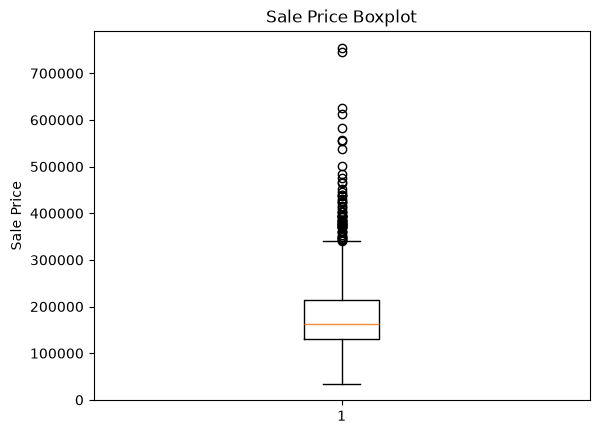

In [11]:
plt.boxplot(df['SalePrice'])
plt.ylabel('Sale Price')
plt.title('Sale Price Boxplot')
plt.savefig(f'{FIG_DIR}/SalePriceBoxplot.png', dpi=600, bbox_inches='tight')
plt.show()

From this boxplot we can see that the median is about 163,000; half the prices fall between 129,975 and 214,000 and there are some outliers with high prices.

### Frequency table and histogram

In [12]:
binnedSalePrice = pd.cut(df['SalePrice'], 10)
binnedSalePrice.value_counts()

SalePrice
(106910.0, 178920.0]    723
(178920.0, 250930.0]    373
(34179.9, 106910.0]     148
(250930.0, 322940.0]    135
(322940.0, 394950.0]     51
(394950.0, 466960.0]     19
(466960.0, 538970.0]      4
(538970.0, 610980.0]      3
(610980.0, 682990.0]      2
(682990.0, 755000.0]      2
Name: count, dtype: int64

Very few houses have a `SalePrice` in the highest bin. The top bin (682990.0, 755000.0] only has two houses.

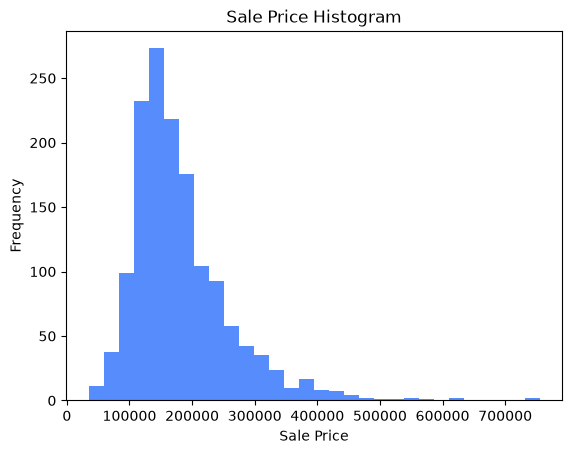

In [13]:
plt.hist(df['SalePrice'], bins=30)
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.title('Sale Price Histogram')
plt.savefig(f'{FIG_DIR}/SalePriceHistogram.png', dpi=600, bbox_inches='tight')
plt.show()

The histogram shows that the distribution is skewed to the right. The majority of houses sold for less than 200,000. There are a few houses that sold for more than 500,000.

### Density plot (log transformed)

> Why log transform?

The log transformation is used to reduce the skewness of the data and make it more normally distributed. This can be useful for certain statistical analyses that assume normality, such as linear regression. Additionally, the log transformation can help to stabilize the variance of the data, which can improve the accuracy of certain statistical models.

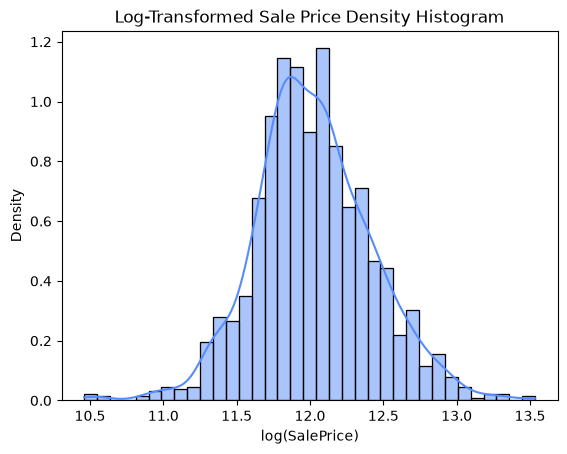

In [14]:
sns.histplot(np.log1p(df['SalePrice']), stat='density', kde=True)
plt.xlabel('log(SalePrice)')
plt.ylabel('Density')
plt.title('Log-Transformed Sale Price Density Histogram')
plt.savefig(f'{FIG_DIR}/LogSalePriceDensity.png', dpi=600, bbox_inches='tight')
plt.show()

The log-transformed SalePrice distribution is approximately normal and substantially less right-skewed than the original distribution. The histogram exhibits a single prominent peak around 12 on the log scale, with only mild positive skewness and few extreme observations. The transformation improves symmetry and makes the variable more suitable for statistical modeling techniques that assume normally distributed residuals.

## Feature Selection

### Numerical features (Correlation)

In [15]:
pearson_corr = df.corr(numeric_only=True, method='pearson')
pearson_corr['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.349876
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
GarageYrBlt      0.261366
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

I am selecting the top 8 numerical features with the highest correlation with SalePrice.

### Categorical features

The Ames Housing dataset contains many categorical variables. `Neighborhood`, `HouseStyle`, `SaleCondition`, and `MSZoning` were selected because they represent four different aspects of a property: location, physical design, transaction circumstances, and zoning classification. Analyzing variables from different domains provides a broader understanding of factors affecting house prices than selecting several variables that describe the same aspect of a property.

## Univariate Analysis of Features

### Numerical Features

#### Histograms and skewness

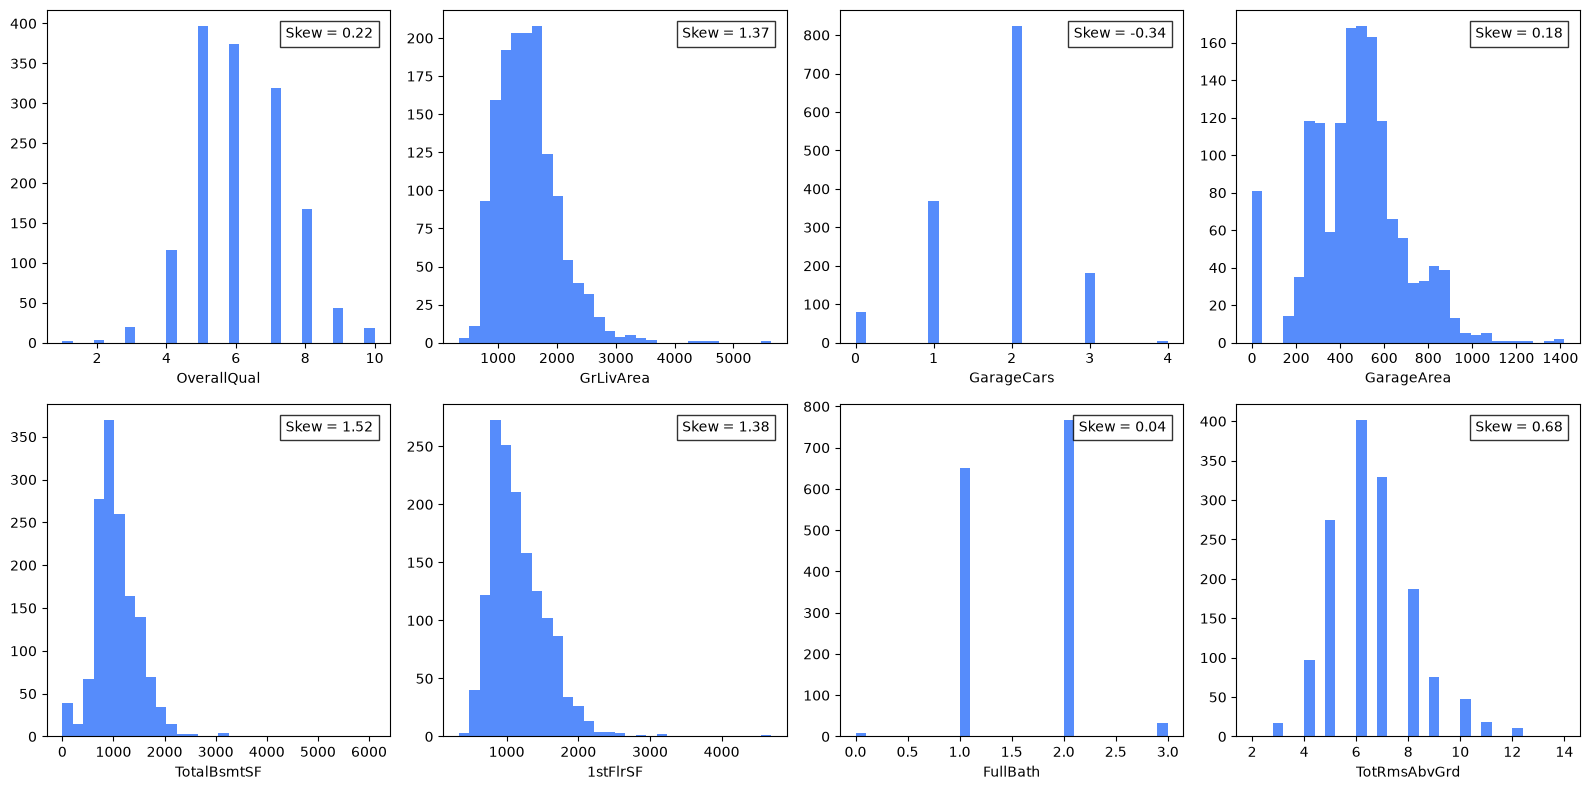

In [16]:
num_cols = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    skewness = df[col].skew()

    ax.hist(df[col], bins=30)
    ax.text(
        0.95, 0.95,
        f'Skew = {skewness:.2f}',
        transform=ax.transAxes,
        ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8)
    )
    ax.set_xlabel(col)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/NumColsHistogram.png', dpi=600, bbox_inches='tight')
plt.show()

From the histograms, we can see that the features `GrLivArea`, `TotalBsmtSF`, and `1stFlrSF` are highly right skewed, and only `GarageCars` is slightly left skewed.

### Categorical Features

#### Frequency bar charts

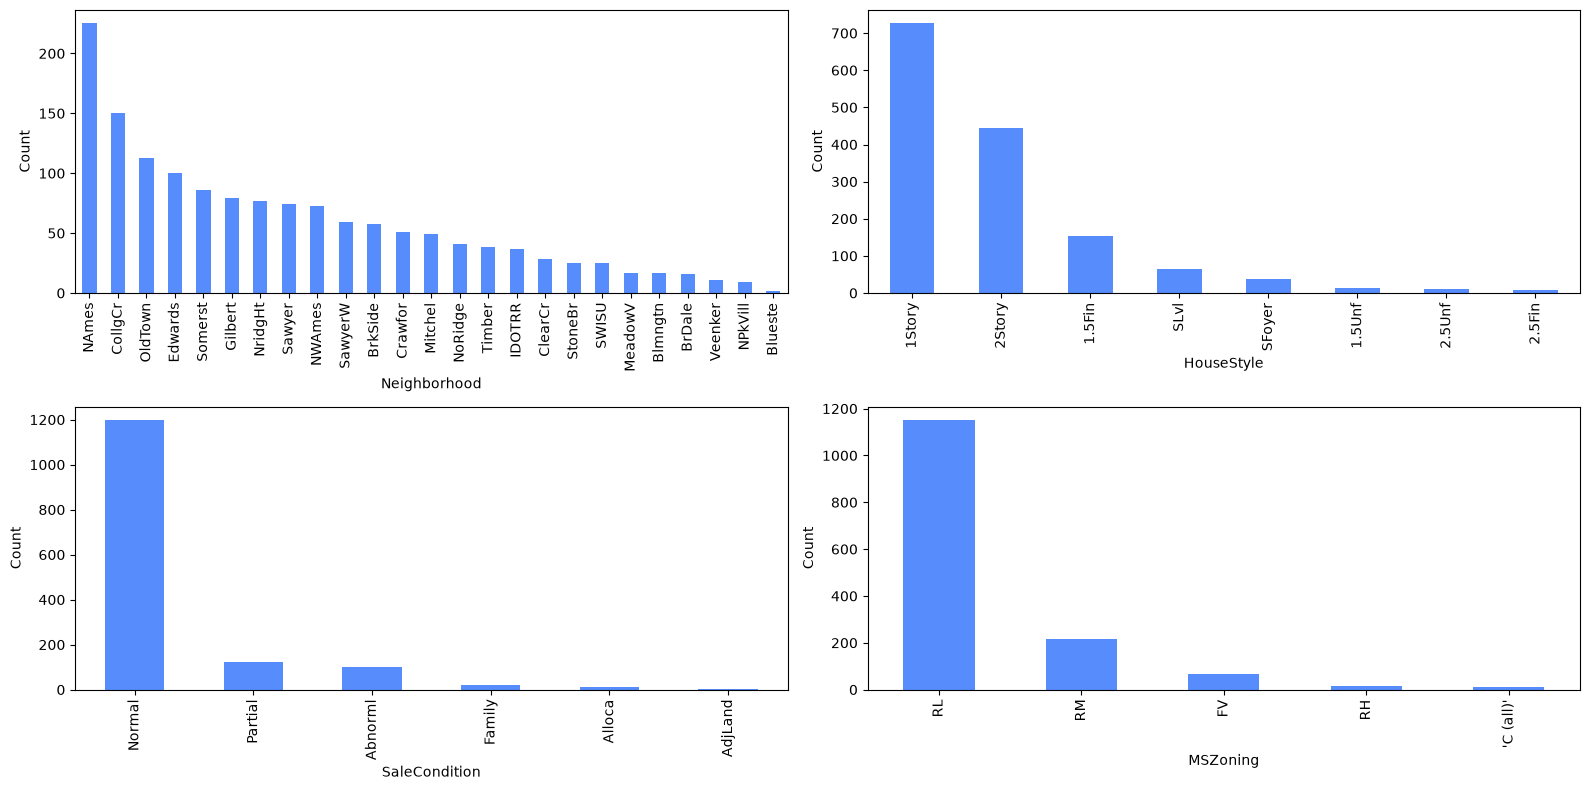

In [17]:
cat_cols = ['Neighborhood', 'HouseStyle', 'SaleCondition', 'MSZoning']

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/CatColsBar.png', dpi=600, bbox_inches='tight')
plt.show()

* NAmes (North Ames) is the most common neighborhood.
* 1Story (one story) is the most common house style.
* Normal is the most common sale condition.
* RL (Residential Low Density) is the most common zoning classification.

#### Cross table between `Neighbourhood` and `SaleCondition`

In [18]:
print(pd.crosstab(df['Neighborhood'], df['SaleCondition']))

SaleCondition  Abnorml  AdjLand  Alloca  Family  Normal  Partial
Neighborhood                                                    
Blmngtn              0        0       0       0      12        5
Blueste              0        0       0       0       2        0
BrDale               3        0       0       1      12        0
BrkSide              3        0       0       1      54        0
ClearCr              3        0       0       0      24        1
CollgCr              3        0       0       0     129       18
Crawfor              3        0       2       2      43        1
Edwards              8        4       2       0      82        4
Gilbert              1        0       0       2      64       12
IDOTRR               7        0       1       0      29        0
MeadowV              1        0       0       0      16        0
Mitchel              3        0       1       2      42        1
NAmes               23        0       0       4     198        0
NPkVill              1   

198 houses in the `NAmes` (North Ames) neighborhood were sold under normal sale condition.

## Bivariate Analysis & Correlation

### Correlation matrix of numeric features against `SalePrice`

#### Pearson method

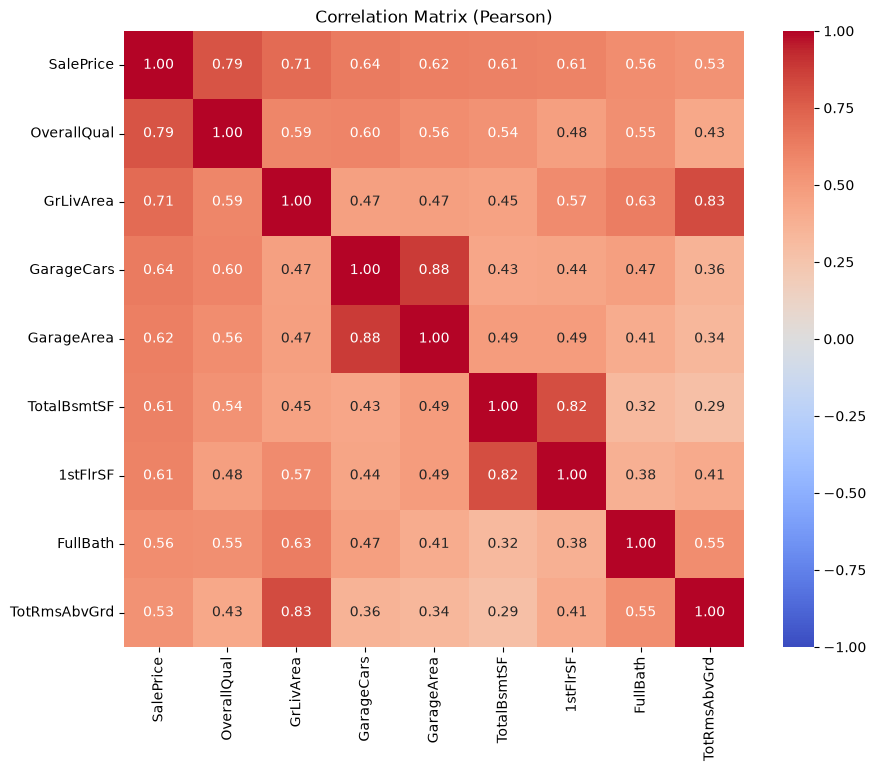

In [19]:
cols = ['SalePrice','OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd']

pearson = df[cols].corr(method='pearson')

plt.figure(figsize=(10, 8))

sns.heatmap(pearson, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix (Pearson)')
plt.savefig(f'{FIG_DIR}/PearsonCorrelationMatrix.png', dpi=600, bbox_inches='tight')
plt.show()

#### Spearman method

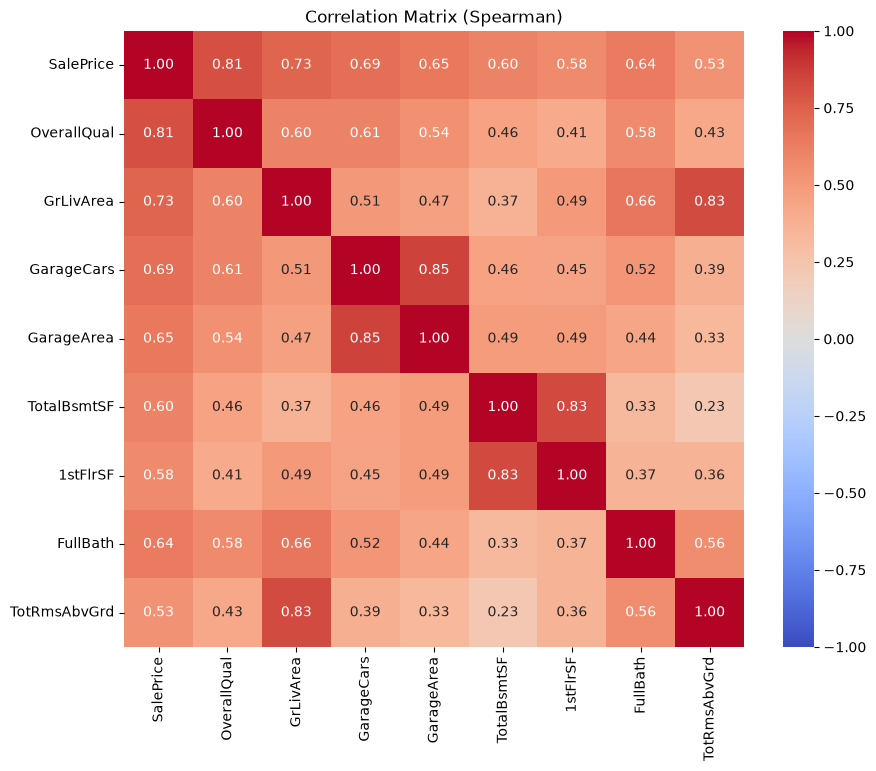

In [20]:
spearman = df[cols].corr(method='spearman')

plt.figure(figsize=(10, 8))

sns.heatmap(spearman, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix (Spearman)')
plt.savefig(f'{FIG_DIR}/SpearmanCorrelationMatrix.png', dpi=600, bbox_inches='tight')
plt.show()

* `OverallQual` and `GrLivArea` are highly correlated to `SalePrice`
* `GrLivArea` and `TotalRmsAbvGrd` are highly correlated to each other.
* `GarageCars` and `GarageArea` are highly correlated to each other.
* `TotalBsmtSF` and `1stFlrSF` are highly correlated to each other.
* `FullBath` and `TotRmsAbvGrd` are highly correlated to each other.

### Scatter plots of numeric columns against `SalePrice`

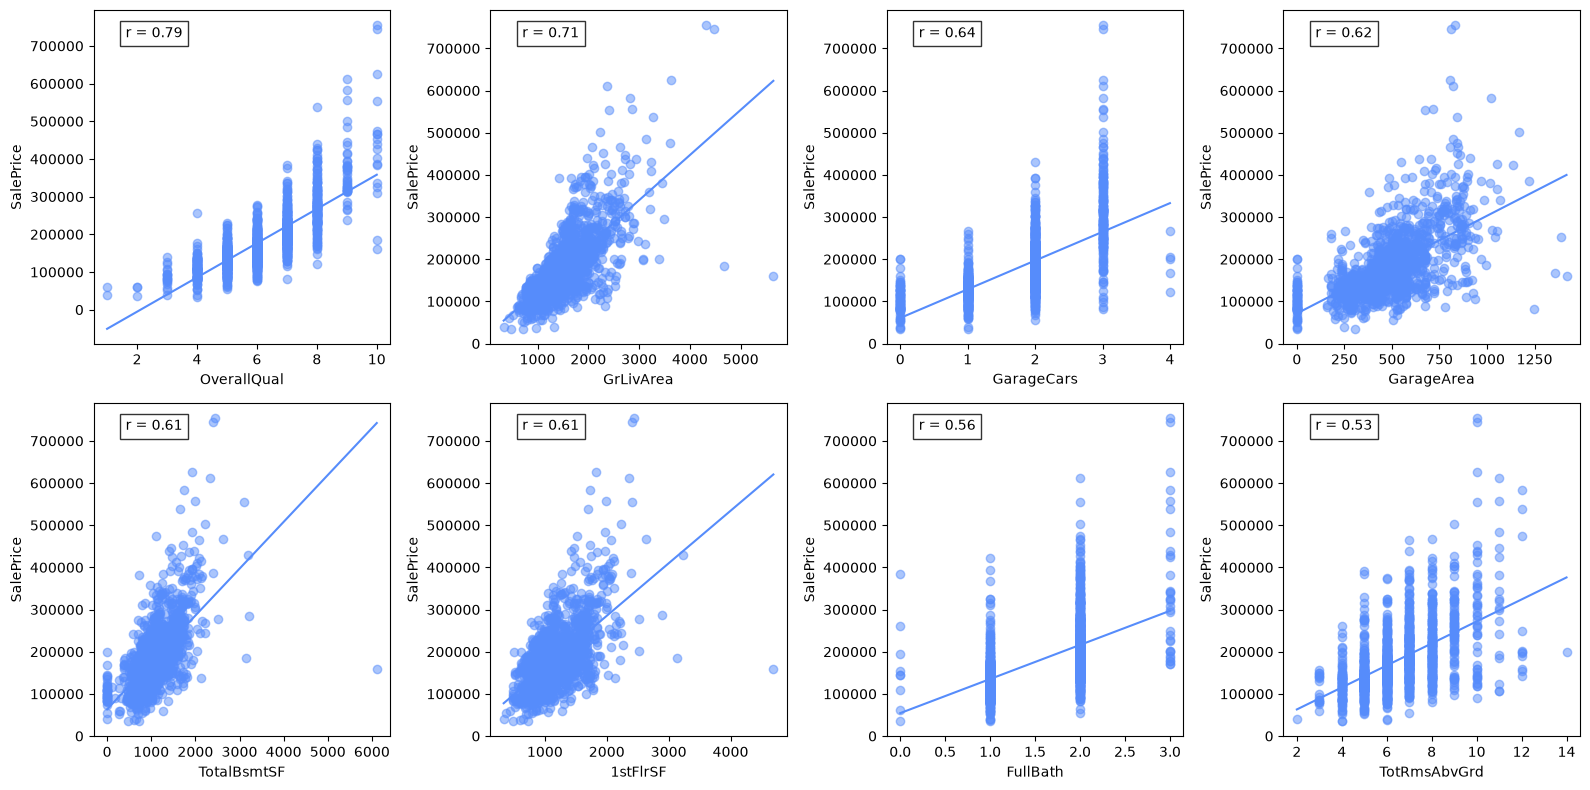

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    x= df[col]
    y= df['SalePrice']

    ax.scatter(x, y, alpha=0.5)

    m,b = np.polyfit(x, y, 1)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = m * x_line + b

    ax.plot(x_line, y_line)

    r = np.corrcoef(x, y)[0, 1]

    ax.text(
        0.3, 0.95,
        f'r = {r:.2f}',
        transform=ax.transAxes,
        ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8)
    )

    ax.set_xlabel(col)
    ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/SalePriceScatterGrid.png', dpi=600, bbox_inches='tight')
plt.show()

All the numeric features have a positive relationship. We can also see some clusters of the data points.

However, for data sets with hundreds of thousands or millions of records, a scatterplot will be too dense, so we need a different way to visualize the relationship – Hexagonal bins & Contour plots.

### Hexagonal binning for numeric columns versus `SalePrice`

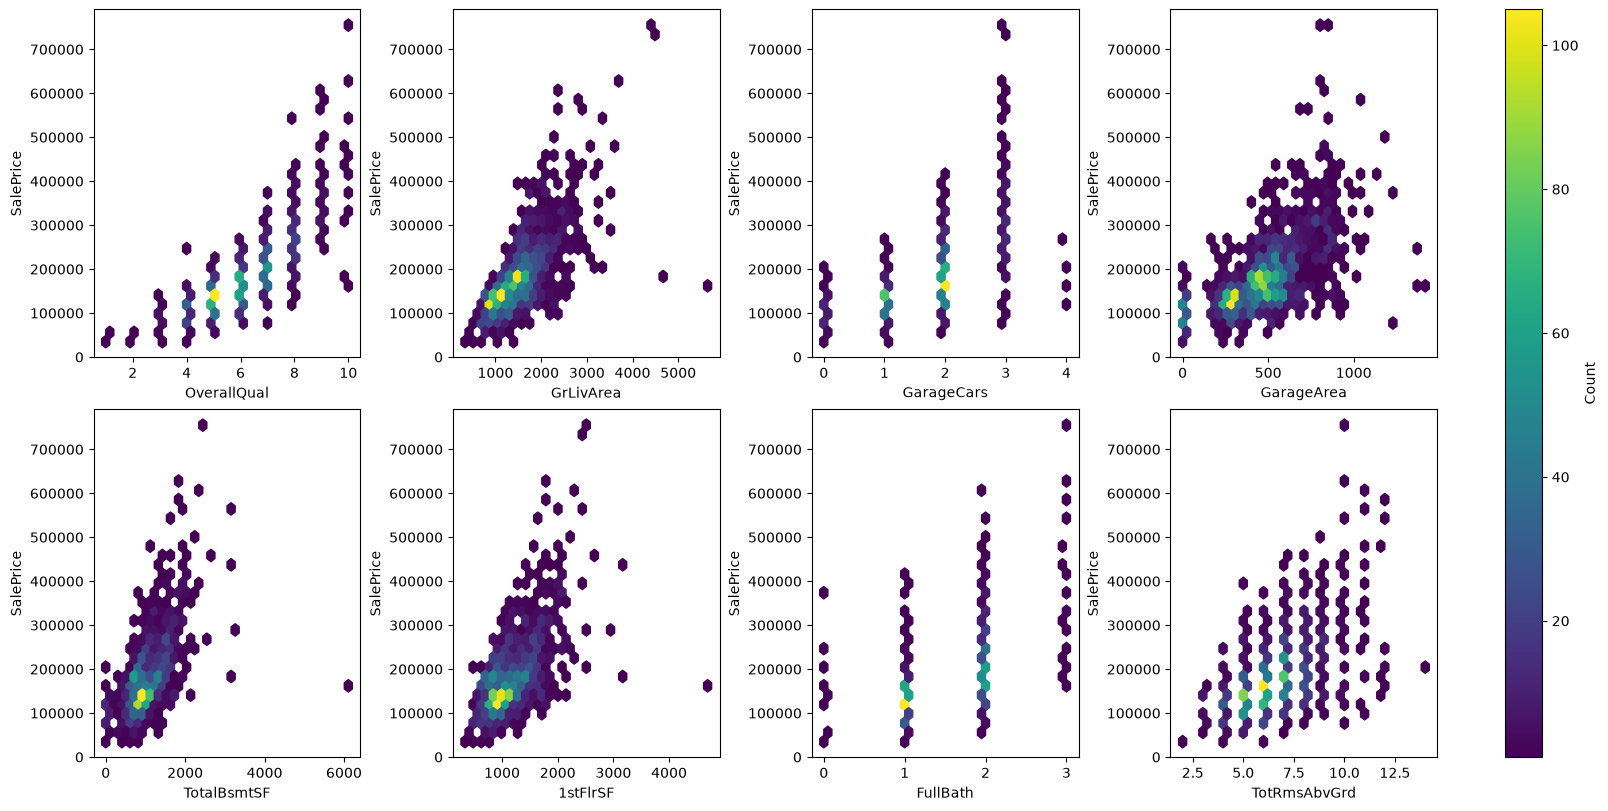

In [22]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8),
    constrained_layout=True
)
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    x = df[col]
    y = df["SalePrice"]

    hb = ax.hexbin(
        x,
        y,
        gridsize=30,
        cmap="viridis",
        mincnt=1
    )

    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice")

fig.colorbar(hb, ax=axes, label="Count")

plt.savefig(f'{FIG_DIR}/SalePriceHexbinGrid.png', dpi=600, bbox_inches='tight')
plt.show()

Rather than plotting individual observations, which would result in significant overplotting, the data are aggregated into **hexagonal bins**. The color intensity of each hexagon represents the number of observations within that region, making it easier to identify areas with the highest concentration of houses.

The highest density of observations is concentrated among houses priced between **100,000** and **200,000**, with **OverallQual** ratings of **4–6**, **GrLivArea** between **1,000 and 1,800 sq. ft.**, **2 garage spaces**, **GarageArea** between **250 and 500 sq. ft.**, approximately **1,000 sq. ft.** of basement and first-floor area, **1 full bathroom**, and **6 rooms above ground**. These characteristics represent the most common types of houses in the dataset and therefore the most frequently observed sales.

### Contour plot for numeric columns versus `SalePrice`

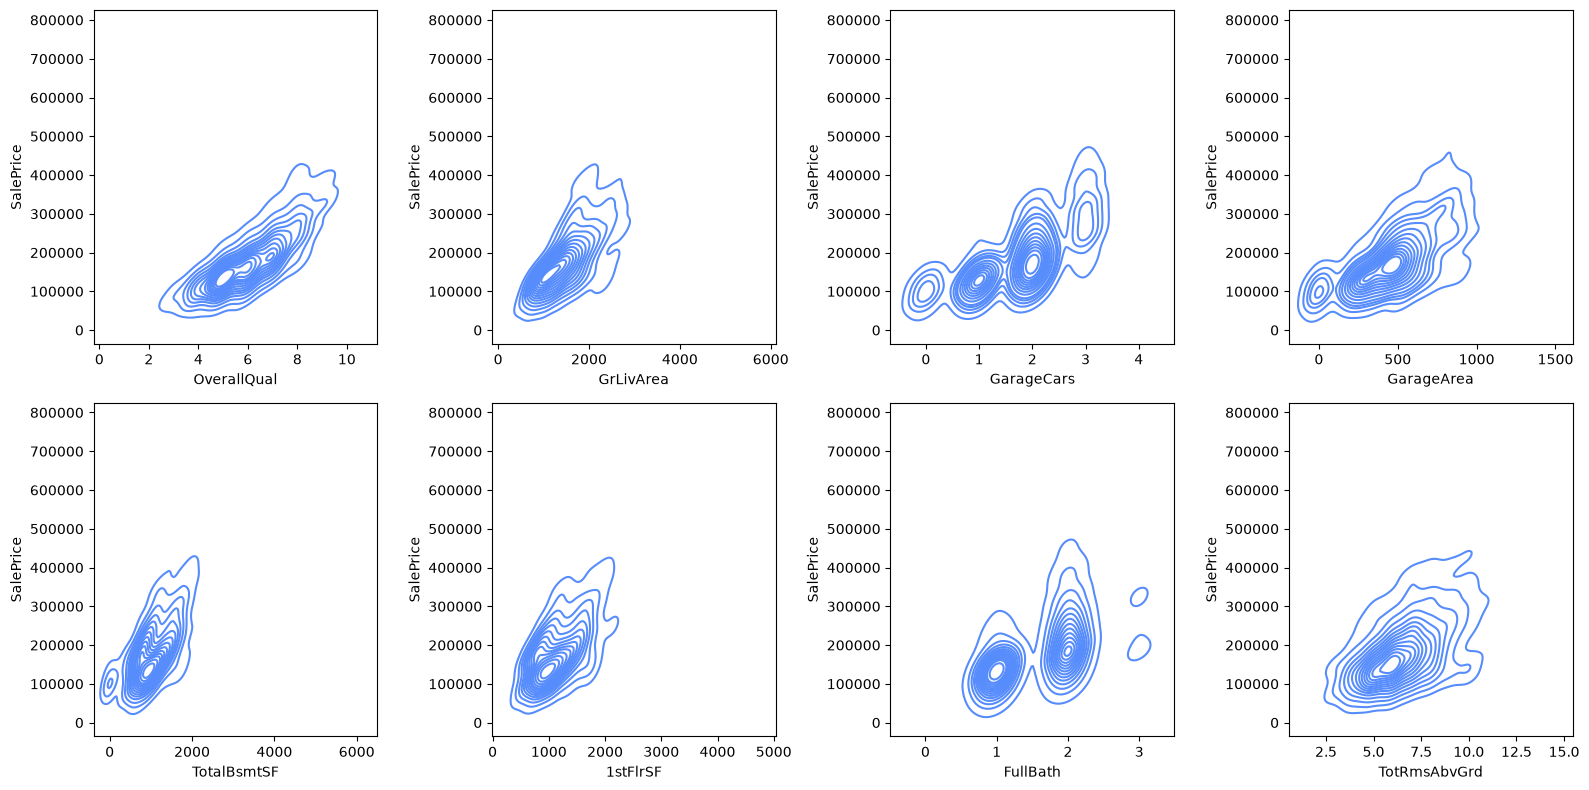

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    x= df[col]
    y= df['SalePrice']

    sns.kdeplot(
        x=x,
        y=y,
        ax=ax,
        levels=15
    )

    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/SalePriceContourGrid.png", dpi=600, bbox_inches="tight")
plt.show()

The contours are essentially a topographical map to two variables; each contour band represents a specific density of points, increasing as one nears a “peak”. We can see that `OverallQual`, `GarageCars`, `GarageArea`, `TotalBsmtSF` and `FullBath` have multiple density points or peaks.

### Violin plot of `OverallQual` against `SalePrice`

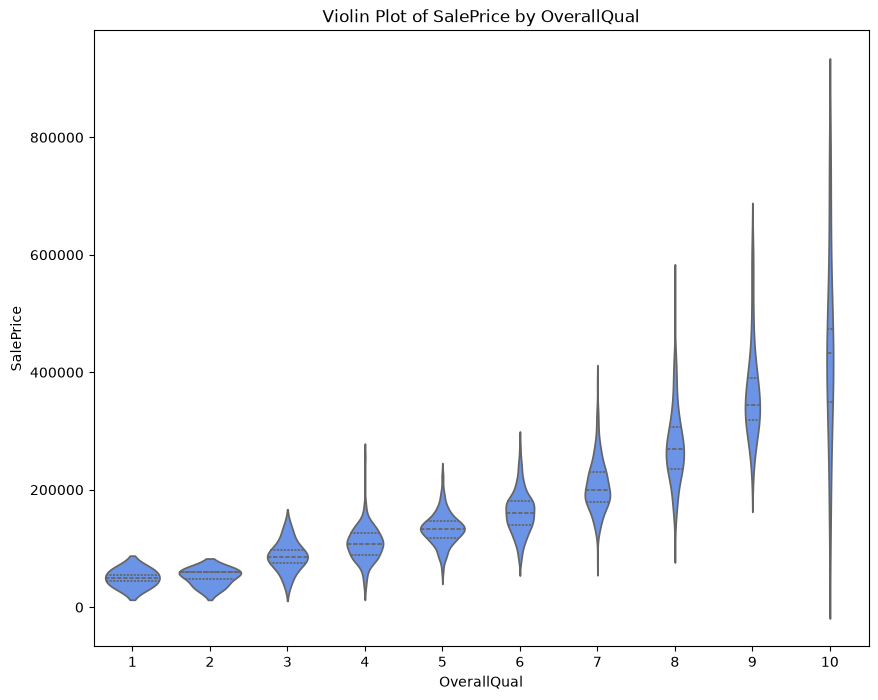

In [24]:
plt.figure(figsize=(10, 8))

ax = sns.violinplot(x=df['OverallQual'], y=df['SalePrice'], inner='quartile')
ax.set_ylabel('SalePrice')
ax.set_xlabel('OverallQual')

plt.title('Violin Plot of SalePrice by OverallQual')
plt.savefig(f'{FIG_DIR}/SalePriceOverallQualViolin.png', dpi=600, bbox_inches='tight')
plt.show()

Houses with lower quality ratings (1–3) are generally concentrated around lower sale prices, whereas higher quality ratings (8–10) are associated with substantially higher median sale prices. The increasing spread of the violins indicates greater price variability among higher-quality homes, consistent with the trends observed in the previous scatter and hexbin plots. Additionally, the width of each violin highlights the price ranges where houses are most densely concentrated for a given quality level.

## Summary

### Dataset Summary

- The dataset contains **1,460 observations** and **81 features** (including the `Id` column).
- It includes **3 numeric float (`float64`)**, **35 numeric integer (`int64`)**, and **43 categorical (`object`)** features (Note: selling year and month are taken as integers).
- Several features contain missing values and require appropriate preprocessing before model development.

### Key Findings

- The distribution of **`SalePrice`** is **positively (right) skewed**, with the mean exceeding the median, indicating the presence of a small number of high-priced properties.
- Applying a **log transformation** to `SalePrice` produces a distribution that is approximately normal and substantially reduces skewness, making it more suitable for regression modeling.
- **`NAmes` (North Ames)** is the most frequently occurring neighborhood in the dataset.
- **`1Story`** is the most common house style.
- **`Normal`** is the predominant sale condition.
- **`RL` (Residential Low Density)** is the most common zoning classification.
- **`OverallQual`** exhibits the strongest positive correlation with `SalePrice`, suggesting that overall material and finish quality is one of the most influential predictors of house prices.